### Neurophysiology and Biophysics - Practical course WS 2024/25
__Cornelia Kopp-Scheinpflug & Kay Thurley__

# Miniproject: Encoding Sound Termination

In this notebook we simulate a neuron from the superior paraolivary nucleus (SPN) in the brainstem. It contains several conductances, i.a. iH channels, and receives inhibitory input from the medial nucleus of the trapezoid body (MNTB).
We use the model by Kopp-Scheinpflug et al. 2011 published on ModelDB. Converted to Python by Kay Thurley (2024).


_Requirements:_ You will need Neuron 8, Python 3 and the package Matplotlib for plotting.


We start by importing the relevant packages.

In [26]:
import numpy as np
from neurom.features.morphology import soma_radius
# import Neuron's hoc interpreter
from neuron import h
h.load_file('stdrun.hoc')

# set default units
from neuron.units import ms, mV

# import matplotlib for plotting
import matplotlib.pyplot as plt
import matplotlib

Then we define the model neuron and some parameters.

In [27]:
# -- default synapse parameters
syninterval = 5                # stimulus interval (ms)
synnum = 25                     # number of stimuli
synnoise = 0                    # could be used to introduce some spike jitter
synconductance = 4e-3           # uS
nsyns = 14                      # how many inhibitory synapses does our neuron have?

gap = 40                        # default gap between the two stimulus trains

# -- load SPN neuron
h.load_file('spn_neuron.hoc')
soma = h.soma(0.5)

Add stimuli and inputs.

In [28]:
# -- synapses
# set up inhibitory synapses
synstim = []
netsynstim = []
syn = []
for i in range(0, nsyns):
    synstim.append(h.NetStims(0.5))
    synstim[-1].start = 200
    synstim[-1].interval = syninterval
    synstim[-1].number = synnum
    synstim[-1].noise = synnoise
    syn.append(h.Exp2Syn(soma))
    syn[-1].e = -100
    syn[-1].tau1 = 0.1
    syn[-1].tau2 = 2
    netsynstim.append(h.NetCon(synstim[-1], syn[-1]))

# second stimulus (after the gap)
synstim2 = []
netsynstim2 = []
for i in range(0, nsyns):
    synstim2.append(h.NetStims(0.5))
    synstim2[-1].start = 300+gap
    synstim2[-1].interval = syninterval
    synstim2[-1].number = synnum
    synstim2[-1].noise = synnoise
    netsynstim2.append(h.NetCon(synstim2[-1], syn[-1]))
 
# -- noise source (simulates excitatory synaptic noise)
fl = h.mhh_Gfluct(0.5)	    # insert conductance based noise
fl.g_e0 = 0.000001		    # amplitude
fl.std_e = 0.0002	        # s-d
fl.tau_e = 2*0              # time constant
fl.E_e = 0                  # reversal potential

# noise
fl.std_e = 0.0005
fl.tau_e = 2

Settings for recording simulation results.

In [29]:
# vectors to store data
t_vec = h.Vector()                  # Time stamp vector
t_vec.record(h._ref_t)
v_vec = h.Vector()                  # membrane potential vector
v_vec.record(soma._ref_v)

syn_vecs = []
for i in range(nsyns):
    syn_vecs.append(h.Vector())
    syn_vecs[-1].record(syn[i]._ref_i)

ih_vec = h.Vector()                  # vector for stimulus current
ih_vec.record(soma.sjg_ih._ref_i)

Vector[84]

Run a simulation.

In [30]:
# syninterval = NetStim[0].interval

# -- set synapse parameters
for i, synsti in enumerate(synstim):
    synsti.start = 300-syninterval*synnum
    synsti.interval = syninterval
    synsti.number = synnum
    synsti.noise = synnoise
    
    synstim2[i].start = 300+gap
    synstim2[i].interval = syninterval
    
    netsynstim[i].weight[0] = synconductance
    netsynstim2[i].weight[0] = synconductance


# -- run a simulation
h.tstop = 750           # duration of the simulation
nspikes = 0             # reset spike counter
h.finitialize(-60)
h.run()

0.0

Plot the results.

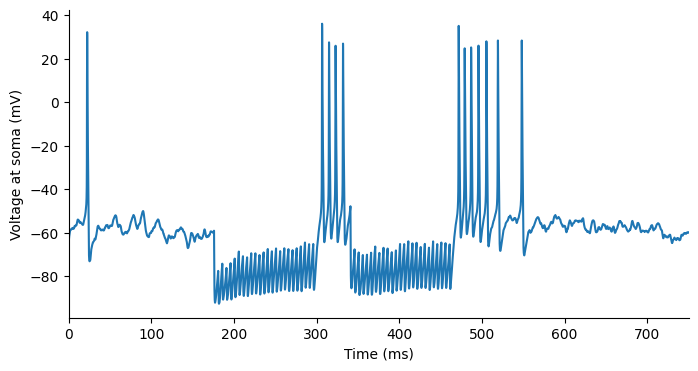

In [31]:
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.set_ylabel('Voltage at soma ('+h.units('v')+')')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('Time ('+h.units('t')+')')
ax.set_xlim([0, h.tstop])

ax.plot(t_vec, v_vec, '-')
